# 08 · Efecto de campañas sin experimento (Complete Journey)

**Sesión 8 · Causalidad observacional** (catálogo: diferencias en diferencias, propensity score e IPW, Double Machine Learning).

Las campañas tipo A 8, 13 y 18 llegaron a ~1.100 hogares cada una, casi todos del Núcleo: **no fueron al azar**. Comparar hogares con y sin campaña mide "ser buen cliente", no el efecto de la campaña. Decisión 011: DiD doblemente robusto como método principal, DML como contraste, y placebo 5 semanas antes.

`python -m growth_lab.campanas`. Usa Complete Journey (`data/interim`); se publican solo agregados.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from growth_lab import db

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
P = db.PROCESSED
ef = pd.read_parquet(P / "cmp_efectos.parquet")
ev = pd.read_parquet(P / "cmp_evento.parquet")
eco = pd.read_parquet(P / "cmp_economia.parquet")

## 1. ¿Venían con la misma tendencia? Estudio de eventos

Brecha semanal de gasto entre tratados y no tratados (ponderados por propensión), relativa al promedio de las 5 semanas previas (la ventana «antes» del DiD). Antes del inicio debería ser plana; si la campaña funciona, sube después de la semana 0.

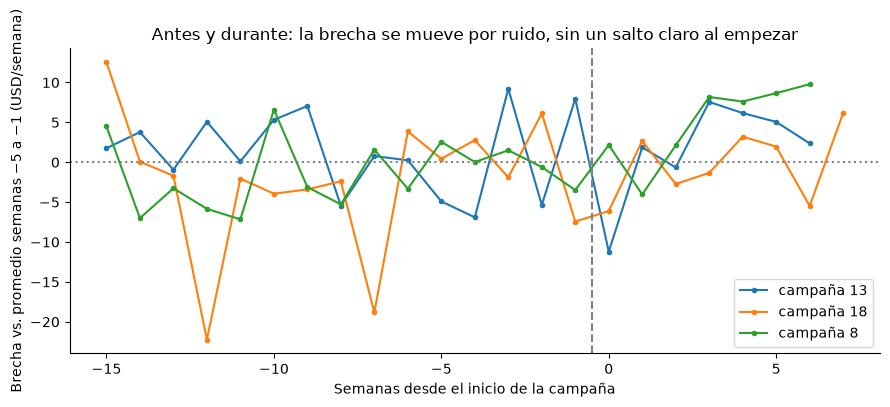

In [2]:
fig, ax = plt.subplots()
for c, g in ev.groupby("campana"):
    ax.plot(g.semana, g.brecha_relativa, marker="o", ms=3, label=f"campaña {c}")
ax.axvline(-0.5, color="grey", ls="--"); ax.axhline(0, color="grey", ls=":")
ax.set_xlabel("Semanas desde el inicio de la campaña"); ax.set_ylabel("Brecha vs. promedio semanas −5 a −1 (USD/semana)")
ax.set_title("Antes y durante: la brecha se mueve por ruido, sin un salto claro al empezar")
ax.legend(); fig.tight_layout(); fig.savefig("../docs/img/cmp_evento.png", dpi=150); plt.show()

## 2. Efecto por método, real y placebo (USD por hogar y semana, IC 95%)

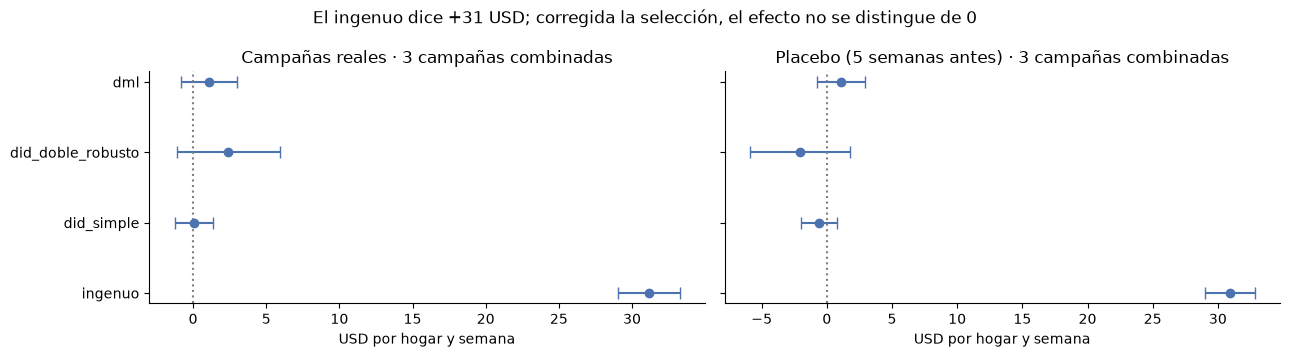

,campana,ventana,metodo,efecto,ic_inf,ic_sup,efecto_pct,hogares,tratados,recortados_por_soporte,tratados_recortados
1,8,real,did_simple,-1.391,-3.773,0.887,-0.025,2108,1066,178.0,9.0
2,8,real,did_doble_robusto,3.600,-2.624,10.830,0.063,2108,1066,178.0,9.0
3,8,real,dml,2.519,-0.576,5.613,0.044,2108,1066,178.0,9.0
5,8,placebo,did_simple,-0.296,-2.782,1.941,-0.005,2067,1062,87.0,13.0
6,8,placebo,did_doble_robusto,-1.090,-6.611,3.955,-0.019,2067,1062,87.0,13.0
7,8,placebo,dml,3.134,-0.026,6.293,0.055,2067,1062,87.0,13.0
9,13,real,did_simple,-0.133,-2.330,2.025,-0.002,1956,985,438.0,92.0
10,13,real,did_doble_robusto,3.070,-2.739,7.774,0.056,1956,985,438.0,92.0
11,13,real,dml,0.419,-2.773,3.611,0.008,1956,985,438.0,92.0
13,13,placebo,did_simple,-0.861,-3.421,1.708,-0.016,1928,993,441.0,84.0


In [3]:
comb = ef[ef.campana == "combinado"]
orden = ["ingenuo", "did_simple", "did_doble_robusto", "dml"]
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for a, ventana in zip(axs, ["real", "placebo"]):
    g = comb[comb.ventana == ventana].set_index("metodo").loc[orden]
    a.errorbar(g.efecto, range(len(g)), xerr=[g.efecto - g.ic_inf, g.ic_sup - g.efecto], fmt="o", capsize=4, color="#4C72B0")
    a.axvline(0, color="grey", ls=":"); a.set_yticks(range(len(g)), g.index)
    a.set_title(f"{'Campañas reales' if ventana == 'real' else 'Placebo (5 semanas antes)'} · 3 campañas combinadas")
    a.set_xlabel("USD por hogar y semana")
fig.suptitle("El ingenuo dice +31 USD; corregida la selección, el efecto no se distingue de 0")
fig.tight_layout(); fig.savefig("../docs/img/cmp_efectos.png", dpi=150); plt.show()
cols = ["campana", "ventana", "metodo", "efecto", "ic_inf", "ic_sup", "efecto_pct", "hogares", "tratados", "recortados_por_soporte", "tratados_recortados"]
ef[ef.metodo != "ingenuo"][cols].round(3)

## 3. ¿Paga los cupones? Y ¿cuánta gente haría falta para saberlo?

`efecto_equilibrio_semanal`: lo mínimo que tiene que subir el gasto de cada hogar para que el margen (30%) pague el descuento de los cupones. `hogares_control_necesarios`: hogares sorteados sin campaña para detectar ese efecto con 80% de potencia (control = 15% de la campaña).

In [4]:
eco.round(2)

,campana,semanas,tratados,gasto_incremental_total,margen_incremental,descuento_cupones_total,efecto_equilibrio_semanal,canjes,tasa_canje_por_hogar,hogares_control_necesarios
0,8,7.00,1075,27092.64,8127.79,2842.01,1.26,372,0.35,5967
1,13,6.86,1077,22669.82,6800.95,3177.56,1.43,629,0.58,4313
2,18,8.00,1133,793.08,237.92,3637.89,1.34,653,0.58,4436


## Mis conclusiones (Neider)

1. **La comparación ingenua engaña:** dice que las campañas suben el gasto 31 USD por semana (+57%), pero los que recibieron la campaña ya eran los mejores clientes. Eso es selección, no efecto.
2. **Corregida la selección, el efecto no se distingue de 0:** el DiD doblemente robusto da +2,4 USD por semana [−1,1; +6,0] combinando las tres campañas. A lo sumo sería +11%.
3. **El método está bien calibrado:** todos los placebos pasan. El DML da lo mismo en lo real que en el placebo, así que su +1,1 es sesgo residual y no efecto.
4. **No se puede saber si pagan los cupones:** harían falta +1,3 USD por hogar y semana, y ese valor queda dentro del intervalo.
5. **Mi recomendación es un grupo de control sorteado,** pero grande: entre 4.300 y 6.000 hogares por campaña para ver ese efecto. Con ~1.100 hogares por campaña hay que acumularlo entre campañas o medir en toda la cadena.
6. **Lo que me llevo:** sin experimento, lo honesto muchas veces es decir "no se puede identificar" y proponer cómo medirlo bien.